# Credit Default: Preprocessing Pipeline and Baseline Model
**Participant 2 | Scope: train/validation split, preprocessing pipeline, baseline model | Language: English**

This notebook continues from Denis's EDA (`Denis_Credit_Default_EDA.ipynb`). It turns the EDA
recommendations into a fitted preprocessing pipeline, splits the original training file into a
training part and a validation part, and trains the baseline model.

**Run:** place this notebook beside `Project_eng.zip` and `credit_pipeline.py`, start a Python 3
kernel and select **Restart Kernel and Run All**. Dependencies: `pandas`, `numpy`, `scikit-learn`,
`matplotlib`.

**Contents:** 1. Load data · 2. Preprocessing decisions · 3. Train/validation split ·
4. Fit and inspect the pipeline · 5. Baseline model · 6. Sensitivity check · 7. Handoff to participant 3.

**Evaluation boundary:** test labels are never loaded here. Every fitted parameter (medians,
scaler statistics, category levels) is learned only on the training part inside `Pipeline.fit`.
The validation part is used for evaluation only. All 750 test rows are kept in their original order.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

import credit_pipeline as cp

pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
OUT = Path('artifacts') / 'participant2'
OUT.mkdir(parents=True, exist_ok=True)

def show(frame, caption):
    display(Markdown(f'**{caption}**'))
    display(frame)

def note(text):
    display(Markdown('**Interpretation.** ' + text))

display(Markdown(f'pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}'))

pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1

## 1. Load data
`cp.load_data()` reads both CSV files straight from the archive and drops the target from the
test file, so the test labels cannot be used by accident.

In [2]:
X_full, y_full, X_test = cp.load_data()
assert X_full.shape == (6750, 16) and X_test.shape == (750, 16)
assert cp.TARGET not in X_test.columns
show(pd.DataFrame({'rows': [len(X_full), len(X_test)], 'predictors': [X_full.shape[1], X_test.shape[1]],
                   'labels loaded': ['yes', 'no']}, index=['train file', 'test file']),
     'Loaded data')

**Loaded data**

,rows,predictors,labels loaded
train file,6750,16,yes
test file,750,16,no


## 2. Preprocessing decisions (from the EDA)
Each step answers a specific EDA finding. Stateless row-wise fixes live in `DomainCleaner`;
everything that learns from data (imputation, scaling, encoding) is fitted on the training part only.

| EDA finding | Decision in the pipeline | Fitted? |
|---|---|---|
| `Credit Score` > 850 in 357 train rows (6060–7510, all divisible by 10) | divide by 10 and keep `score_scale_flag` | no |
| `Current Loan Amount` = 99999999 in 783 train rows | treat as unknown (NaN → median) and keep `loan_sentinel_flag` | median: yes |
| `Annual Income` and `Credit Score` missing in exactly the same 1,400 rows | median imputation + **one** shared indicator `income_score_missing` | median: yes |
| `Months since last delinquent` missing in 54% of rows | median imputation + `delinquent_missing` indicator | median: yes |
| `Years in current job` stored as text, 332 missing | ordinal 0–10, median imputation + `tenure_missing` | median: yes |
| `Bankruptcies` missing in 12 rows | median imputation (count-aware, median is 0) | median: yes |
| Long right tails in monetary columns | `log1p` before scaling (linear model) | no |
| Different numeric scales | `StandardScaler` | yes |
| 3 nominal categoricals, rare levels (e.g. `Have Mortgage` n=10) | one-hot, levels with < 20 train rows grouped as infrequent, unknown-safe | yes |
| 28.5% class 1 | stratified split, `class_weight='balanced'`, report Precision / Recall / F1 | — |
| Extreme values (e.g. `Maximum Open Credit`) | no rows deleted, no clipping; log transform reduces their leverage | — |

**Open question carried over from the EDA:** the two anomaly flags separate the classes almost
perfectly in train (all score > 850 rows are class 1, all loan = 99999999 rows are class 0).
We keep them in the baseline because the information is already present in the raw values,
but section 6 measures how much of the score depends on them.

## 3. Train/validation split
Stratified 80/20 split of the original training file with `random_state=42`. The row indices
are saved to `artifacts/participant2/split_indices.csv` so participant 3 evaluates every model on
exactly the same validation rows.

In [3]:
idx_tr, idx_va = cp.make_split(y_full)
X_tr, y_tr = X_full.loc[idx_tr], y_full.loc[idx_tr]
X_va, y_va = X_full.loc[idx_va], y_full.loc[idx_va]
assert idx_tr.intersection(idx_va).empty and len(idx_tr) + len(idx_va) == len(X_full)

split_table = pd.DataFrame({
    'rows': [len(y_tr), len(y_va), len(y_full)],
    'class 0': [int((y_tr == 0).sum()), int((y_va == 0).sum()), int((y_full == 0).sum())],
    'class 1': [int(y_tr.sum()), int(y_va.sum()), int(y_full.sum())],
    'class 1 %': [y_tr.mean() * 100, y_va.mean() * 100, y_full.mean() * 100],
}, index=['training part', 'validation part', 'original train file'])
show(split_table, 'Stratified split preserves the class balance')

split_df = pd.concat([pd.DataFrame({'row': idx_tr, 'part': 'train'}),
                      pd.DataFrame({'row': idx_va, 'part': 'valid'})]).sort_values('row')
split_df.to_csv(cp.SPLIT_FILE, index=False)
loaded_tr, loaded_va = cp.load_split()
assert loaded_tr.equals(idx_tr) and loaded_va.equals(idx_va)
note('Both parts keep the 28.5% share of class 1, so validation metrics are not distorted '
     'by a different class balance. The saved split reloads identically.')

**Stratified split preserves the class balance**

,rows,class 0,class 1,class 1 %
training part,5400,3860,1540,28.5185
validation part,1350,965,385,28.5185
original train file,6750,4825,1925,28.5185


**Interpretation.** Both parts keep the 28.5% share of class 1, so validation metrics are not distorted by a different class balance. The saved split reloads identically.

## 4. Fit and inspect the preprocessing pipeline
The preprocessor is fitted on the training part only, then applied unchanged to the validation part
and to the test predictors. We check that the output has no missing values and the same columns
everywhere.

In [4]:
pre = cp.build_preprocessor()
Z_tr = pre.fit_transform(X_tr)
Z_va = pre.transform(X_va)
Z_test = pre.transform(X_test)
feature_names = pre.named_steps['columns'].get_feature_names_out()

for name, Z in [('training part', Z_tr), ('validation part', Z_va), ('test predictors', Z_test)]:
    assert not np.isnan(Z).any(), name
    assert Z.shape[1] == len(feature_names)
show(pd.DataFrame({'rows': [Z_tr.shape[0], Z_va.shape[0], Z_test.shape[0]],
                   'features after preprocessing': [Z_tr.shape[1], Z_va.shape[1], Z_test.shape[1]],
                   'missing values': [int(np.isnan(Z).sum()) for Z in (Z_tr, Z_va, Z_test)]},
                  index=['training part', 'validation part', 'test predictors']),
     'Pipeline output: no missing values, identical feature space')

display(Markdown('**Output features (' + str(len(feature_names)) + '):** ' + ', '.join(f'`{f}`' for f in feature_names)))

**Pipeline output: no missing values, identical feature space**

,rows,features after preprocessing,missing values
training part,5400,34,0
validation part,1350,34,0
test predictors,750,34,0


**Output features (34):** `Annual Income`, `Maximum Open Credit`, `Current Loan Amount`, `Current Credit Balance`, `Monthly Debt`, `Tax Liens`, `Number of Open Accounts`, `Years of Credit History`, `Number of Credit Problems`, `Months since last delinquent`, `Bankruptcies`, `Credit Score`, `Years in current job`, `income_score_missing`, `delinquent_missing`, `tenure_missing`, `score_scale_flag`, `loan_sentinel_flag`, `Home Ownership_Home Mortgage`, `Home Ownership_Own Home`, `Home Ownership_Rent`, `Home Ownership_infrequent_sklearn`, `Purpose_business loan`, `Purpose_buy a car`, `Purpose_buy house`, `Purpose_debt consolidation`, `Purpose_home improvements`, `Purpose_major purchase`, `Purpose_medical bills`, `Purpose_other`, `Purpose_take a trip`, `Purpose_infrequent_sklearn`, `Term_Long Term`, `Term_Short Term`

**Training part: effect of the row-wise fixes**

,before,after DomainCleaner
Credit Score > 850,298.0000,0.0000
Loan = 99999999,632.0000,0.0000
Tenure missing (imputed later),263.0000,263.0000
max Credit Score,"7,510.0000",751.0000


**Imputation values (fitted on the training part only)**

,median learned on training part
Annual Income,"1,167,930.0000"
Maximum Open Credit,"478,170.0000"
Current Loan Amount,"265,298.0000"
Current Credit Balance,"208,050.0000"
Monthly Debt,"16,151.0000"
Tax Liens,0.0000
Number of Open Accounts,10.0000
Years of Credit History,17.0000
Number of Credit Problems,0.0000
Months since last delinquent,32.0000


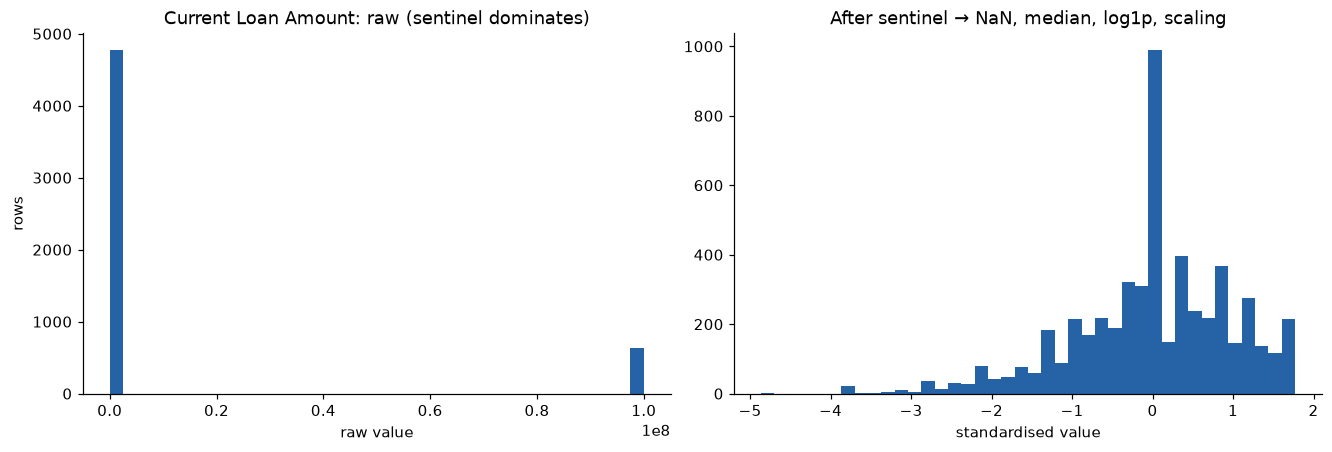

**Interpretation.** The score-scale and sentinel fixes are applied, tenure is numeric, and every missing value is filled with a median learned on the training part. The loan-amount sentinel no longer stretches the scale; its information is kept in `loan_sentinel_flag`.

In [5]:
clean_tr = cp.DomainCleaner().transform(X_tr)
check = pd.DataFrame({
    'before': [int(X_tr['Credit Score'].gt(850).sum()), int(X_tr['Current Loan Amount'].eq(cp.LOAN_SENTINEL).sum()),
               int(X_tr['Years in current job'].isna().sum()), X_tr['Credit Score'].max()],
    'after DomainCleaner': [int(clean_tr['Credit Score'].gt(850).sum()),
                            int(clean_tr['Current Loan Amount'].eq(cp.LOAN_SENTINEL).sum()),
                            int(clean_tr['Years in current job'].isna().sum()), clean_tr['Credit Score'].max()],
}, index=['Credit Score > 850', 'Loan = 99999999', 'Tenure missing (imputed later)', 'max Credit Score'])
show(check, 'Training part: effect of the row-wise fixes')

num = pre.named_steps['columns'].named_transformers_
medians = pd.Series(np.r_[num['money'][0].statistics_, num['numeric'][0].statistics_],
                    index=cp.MONEY_COLS + cp.OTHER_NUMERIC_COLS, name='median learned on training part')
show(medians.to_frame(), 'Imputation values (fitted on the training part only)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
raw = X_tr['Current Loan Amount']
axes[0].hist(raw, bins=40, color='#2563a6')
axes[0].set(title='Current Loan Amount: raw (sentinel dominates)', xlabel='raw value', ylabel='rows')
money_idx = list(feature_names).index('Current Loan Amount')
axes[1].hist(Z_tr[:, money_idx], bins=40, color='#2563a6')
axes[1].set(title='After sentinel → NaN, median, log1p, scaling', xlabel='standardised value')
plt.show()
note('The score-scale and sentinel fixes are applied, tenure is numeric, and every missing value '
     'is filled with a median learned on the training part. The loan-amount sentinel no longer '
     'stretches the scale; its information is kept in `loan_sentinel_flag`.')

## 5. Baseline model
**Baseline: logistic regression** (`class_weight='balanced'`, `max_iter=2000`). It is simple,
fast and interpretable, needs scaled inputs (which the pipeline provides), and gives a clear
reference point for participant 3's stronger models. A `DummyClassifier` (always predicts the
majority class) shows the floor. Metrics are reported for **class 1** with the default
threshold 0.5; threshold tuning is left to the model-comparison stage and must use validation data only.

In [6]:
def make_model(estimator, **pre_kwargs):
    return Pipeline([('preprocess', cp.build_preprocessor(**pre_kwargs)), ('model', estimator)])

def scores(y_true, y_pred):
    return {'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred),
            'Accuracy': accuracy_score(y_true, y_pred)}

baseline = make_model(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=cp.RANDOM_STATE))
dummy = make_model(DummyClassifier(strategy='most_frequent'))
baseline.fit(X_tr, y_tr)
dummy.fit(X_tr, y_tr)

val_pred = baseline.predict(X_va)
val_proba = baseline.predict_proba(X_va)[:, 1]
results = pd.DataFrame({
    'Dummy (majority class)': scores(y_va, dummy.predict(X_va)),
    'Logistic regression (baseline)': scores(y_va, val_pred),
}).T
show(results, 'Validation part: class-1 metrics')
print(classification_report(y_va, val_pred, digits=3))

**Validation part: class-1 metrics**

,Precision,Recall,F1,Accuracy
Dummy (majority class),0.0000,0.0000,0.0000,0.7148
Logistic regression (baseline),0.4577,0.6468,0.5361,0.6807


              precision    recall  f1-score   support

           0      0.831     0.694     0.757       965
           1      0.458     0.647     0.536       385

    accuracy                          0.681      1350
   macro avg      0.644     0.671     0.646      1350
weighted avg      0.725     0.681     0.694      1350



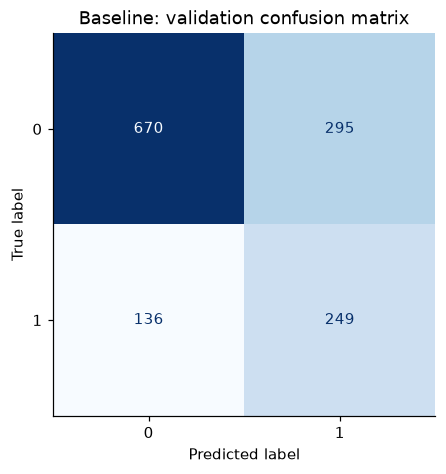

**5-fold stratified CV on the training part (preprocessing refitted inside each fold)**

,precision,recall,f1
fold 1,0.4807,0.6461,0.5512
fold 2,0.4642,0.6526,0.5425
fold 3,0.4774,0.6851,0.5627
fold 4,0.4930,0.6851,0.5734
fold 5,0.4799,0.6201,0.5411
mean,0.4790,0.6578,0.5542
std,0.0103,0.0277,0.0138


In [7]:
fig, ax = plt.subplots(figsize=(4.8, 4.2), layout='constrained')
ConfusionMatrixDisplay(confusion_matrix(y_va, val_pred), display_labels=['0', '1']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set(title='Baseline: validation confusion matrix')
plt.show()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=cp.RANDOM_STATE)
cv_res = cross_validate(make_model(LogisticRegression(class_weight='balanced', max_iter=2000,
                                                      random_state=cp.RANDOM_STATE)),
                        X_tr, y_tr, cv=cv, scoring=['precision', 'recall', 'f1'])
cv_table = pd.DataFrame({m: cv_res[f'test_{m}'] for m in ['precision', 'recall', 'f1']})
cv_table.index = [f'fold {i + 1}' for i in range(len(cv_table))]
cv_table.loc['mean'] = cv_table.mean()
cv_table.loc['std'] = cv_table.iloc[:5].std()
show(cv_table, '5-fold stratified CV on the training part (preprocessing refitted inside each fold)')

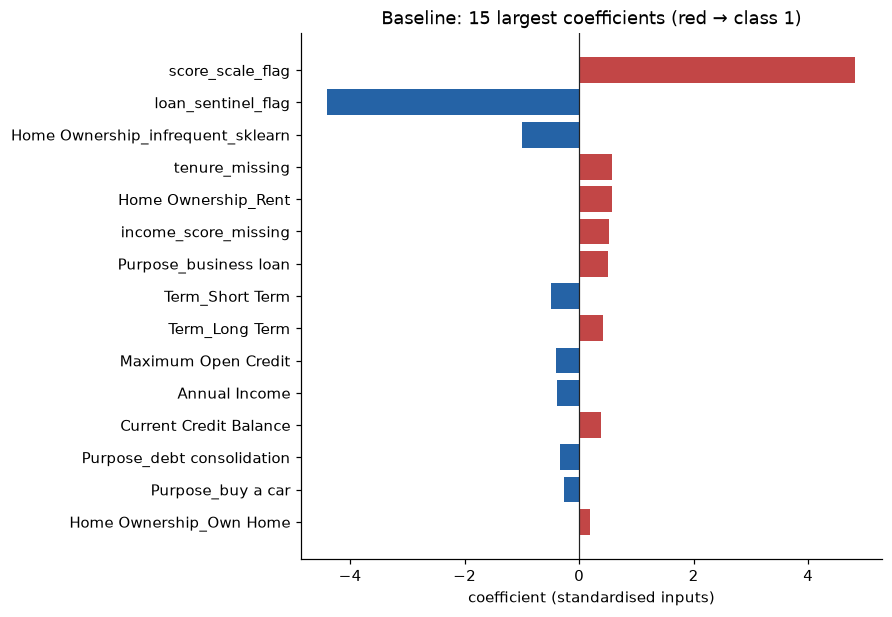

**Interpretation.** The baseline reaches Precision 0.458, Recall 0.647 and F1 0.536 for class 1 on the validation part; the dummy model has F1 = 0 because it never predicts class 1. The 5-fold CV F1 (0.554 ± 0.014) is close to the validation score, so the estimate is stable. `class_weight="balanced"` trades precision for recall. The largest coefficients belong to the anomaly flags, which motivates the sensitivity check below.

In [8]:
coefs = pd.Series(baseline.named_steps['model'].coef_[0],
                  index=baseline.named_steps['preprocess'].named_steps['columns'].get_feature_names_out())
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(figsize=(8, 5.5), layout='constrained')
ax.barh(top.index[::-1], top.values[::-1], color=['#c24646' if v > 0 else '#2563a6' for v in top.values[::-1]])
ax.axvline(0, color='#222', linewidth=0.8)
ax.set(title='Baseline: 15 largest coefficients (red → class 1)', xlabel='coefficient (standardised inputs)')
plt.show()
r = results.loc['Logistic regression (baseline)']
note(f'The baseline reaches Precision {r.Precision:.3f}, Recall {r.Recall:.3f} and F1 {r.F1:.3f} for class 1 '
     f'on the validation part; the dummy model has F1 = 0 because it never predicts class 1. '
     f'The 5-fold CV F1 ({cv_table.loc["mean", "f1"]:.3f} ± {cv_table.loc["std", "f1"]:.3f}) is close to the validation '
     'score, so the estimate is stable. `class_weight="balanced"` trades precision for recall. '
     'The largest coefficients belong to the anomaly flags, which motivates the sensitivity check below.')

## 6. Sensitivity check: anomaly flags
Same model and split, but `score_scale_flag` and `loan_sentinel_flag` are removed (the corrected
score and the imputed loan amount remain). This shows how dependent the baseline is on the two
patterns that the EDA marked as possible artefacts or leakage.

In [9]:
no_flags = make_model(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=cp.RANDOM_STATE),
                      use_anomaly_flags=False)
no_flags.fit(X_tr, y_tr)
sensitivity = pd.DataFrame({
    'with anomaly flags (baseline)': scores(y_va, val_pred),
    'without anomaly flags': scores(y_va, no_flags.predict(X_va)),
}).T
show(sensitivity, 'Validation part: effect of the anomaly flags')
drop = sensitivity.iloc[0]['F1'] - sensitivity.iloc[1]['F1']
note(f'Removing the two flags changes validation F1 by {-drop:+.3f}. A large share of the signal comes from '
     'these patterns. If the team confirms they are recorded *before* the credit decision, they are legitimate '
     'features; if not, the "without flags" number is the honest estimate. Participant 3 should report both.')

**Validation part: effect of the anomaly flags**

,Precision,Recall,F1,Accuracy
with anomaly flags (baseline),0.4577,0.6468,0.5361,0.6807
without anomaly flags,0.3898,0.5974,0.4718,0.6185


**Interpretation.** Removing the two flags changes validation F1 by -0.064. A large share of the signal comes from these patterns. If the team confirms they are recorded *before* the credit decision, they are legitimate features; if not, the "without flags" number is the honest estimate. Participant 3 should report both.

## 7. Handoff to participant 3
Saved to `artifacts/participant2/`:

* `split_indices.csv` — row index and part (`train` / `valid`); load with `cp.load_split()`.
* `baseline_validation_metrics.csv` — baseline, dummy and no-flags metrics on the validation part.
* `baseline_validation_predictions.csv` — validation row, true label, baseline probability and prediction (for error analysis).
* `baseline_summary.json` — configuration and metrics.

How to reuse the same setup:

```python
import credit_pipeline as cp
X_full, y_full, X_test = cp.load_data()
idx_tr, idx_va = cp.load_split()
pre = cp.build_preprocessor(scale=False)   # tree models; scale=True for linear/distance models
```

Rules: compare all models on the same validation rows with Precision, Recall and F1 for class 1;
choose hyperparameters and thresholds on the training/validation data only; call
`cp.load_test_labels()` only once, for the final evaluation of the already chosen model.

In [10]:
metrics_out = pd.concat([results, sensitivity.iloc[[1]]])
metrics_out.index.name = 'model'
metrics_out.to_csv(OUT / 'baseline_validation_metrics.csv')
pd.DataFrame({'row': idx_va, 'y_true': y_va.to_numpy(), 'proba_class_1': val_proba,
              'y_pred': val_pred}).to_csv(OUT / 'baseline_validation_predictions.csv', index=False)
summary = {
    'split': {'method': 'stratified train_test_split', 'valid_size': cp.VALID_SIZE,
              'random_state': cp.RANDOM_STATE, 'train_rows': len(idx_tr), 'valid_rows': len(idx_va)},
    'baseline': {'model': 'LogisticRegression', 'class_weight': 'balanced', 'max_iter': 2000, 'threshold': 0.5},
    'features_after_preprocessing': list(map(str, feature_names)),
    'validation_metrics': {k: {m: round(float(v), 4) for m, v in row.items()} for k, row in metrics_out.iterrows()},
    'cv_training_part': {m: {'mean': round(float(cv_table.loc['mean', m]), 4), 'std': round(float(cv_table.loc['std', m]), 4)}
                         for m in cv_table.columns},
}
(OUT / 'baseline_summary.json').write_text(json.dumps(summary, indent=2))
show(pd.DataFrame({'file': sorted(p.name for p in OUT.iterdir())}), 'Saved artefacts')

**Saved artefacts**

,file
0,baseline_summary.json
1,baseline_validation_metrics.csv
2,baseline_validation_predictions.csv
3,split_indices.csv


In [11]:
# Integrity checks
X_full_again, y_full_again, X_test_again = cp.load_data()
pd.testing.assert_frame_equal(X_full, X_full_again)
pd.testing.assert_frame_equal(X_test, X_test_again)
assert len(X_test) == 750 and X_test.index.equals(pd.RangeIndex(750))
assert Z_test.shape[0] == 750
assert cp.TARGET not in X_test.columns
display(Markdown('**ALL CHECKS PASSED** — source data unchanged, 750 test rows preserved in order, '
                 'test labels never loaded, all preprocessing fitted on the training part only.'))

**ALL CHECKS PASSED** — source data unchanged, 750 test rows preserved in order, test labels never loaded, all preprocessing fitted on the training part only.